# Tuần 3 bổ sung: boosting, chẩn đoán overfit, độ quan trọng đặc trưng, đường cong học

Notebook chỉ **hiển thị** kết quả đã tính (chỉ dùng tập **train**, không đọc tập test).
**Boosting chưa được đánh giá trên test** (tập test đã dùng một lần cho các mô hình đã đóng băng).
Báo cáo đầy đủ: `reports/week3_extra_report.md`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 220, 'display.max_columns', 30, 'display.float_format', '{:,.2f}'.format, 'display.max_colwidth', 90)
T, F = ROOT / 'reports' / 'tables', ROOT / 'reports' / 'figures'
best = json.loads((ROOT / 'reports' / 'week3_hgb_best.json').read_text(encoding='utf-8'))
print('Boosting được chọn:', best['final']['encoder'], '| log giá:', best['final']['log_target'])
print(best['final']['params'])

Boosting được chọn: target | log giá: True
{'l2_regularization': 10.0, 'learning_rate': 0.05, 'max_depth': None, 'max_iter': 800, 'max_leaf_nodes': 127, 'min_samples_leaf': 20}


## 1. Boosting tinh chỉnh trên toàn train (CV 5 fold)

,model,source,mae_mean,mae_std,rmse_mean,r2_mean,medape_mean,fit_seconds,hgb_best_wins_folds
0,knn_default,"tuần 2, mặc định, toàn train","8,079.90",288.16,"55,364.71",0.78,9.92,1.05,5.00
1,ridge_default,"tuần 2, mặc định, toàn train","15,740.86",262.23,"66,248.59",0.70,24.42,1.91,5.00
2,rf_default,"tuần 2, mặc định, toàn train","6,276.04",216.10,"49,383.58",0.83,7.61,"1,162.45",5.00
3,hgb_default,"tuần 3, mặc định, toàn train","7,240.18",329.85,"54,298.07",0.78,9.08,18.56,5.00
4,hgb_best,"tuần 3, đã tinh chỉnh, toàn train","5,880.39",211.92,"47,302.20",0.83,7.42,183.39,NaN


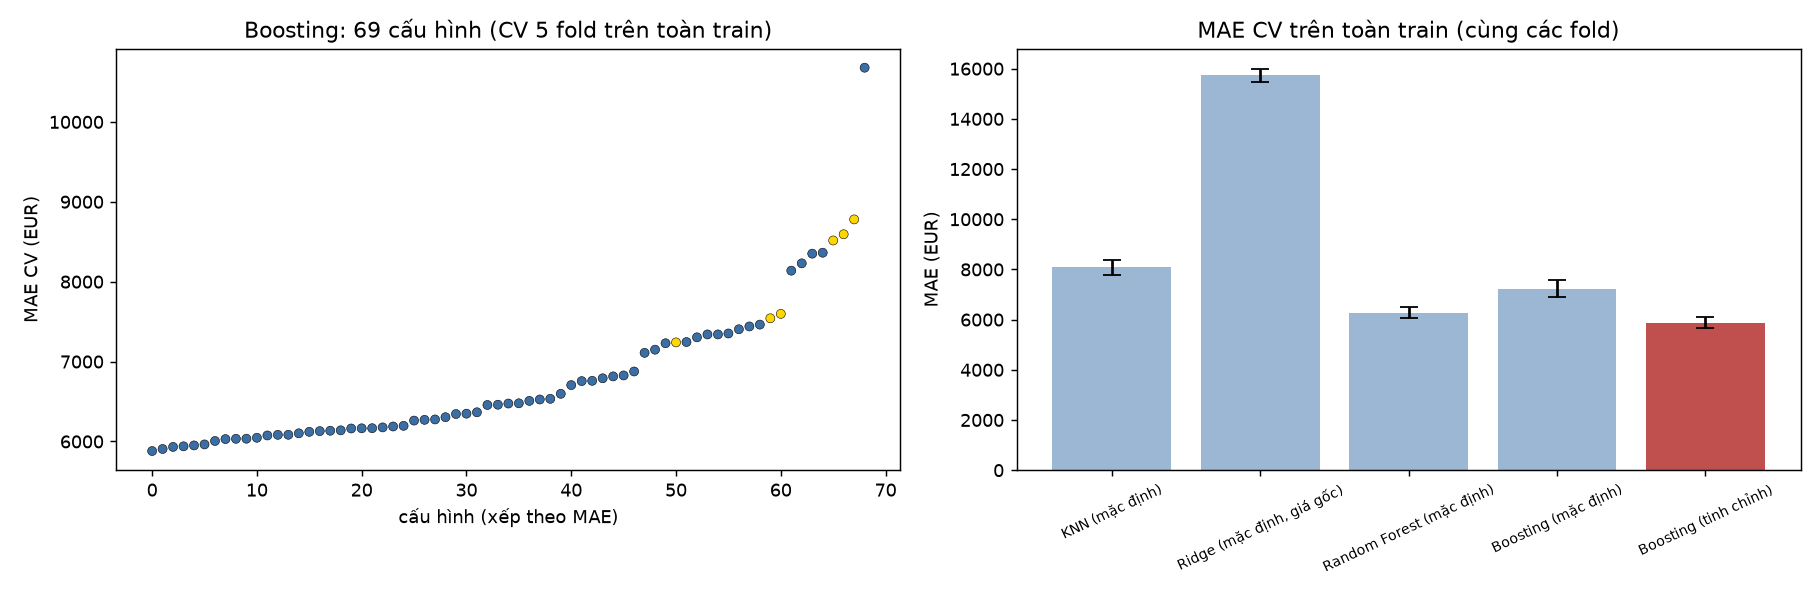

In [2]:
display(pd.read_csv(T / 'week3_hgb_vs_models_fullcv.csv'))
display(Image(str(F / 'week3_hgb.png')))

In [3]:
pd.read_csv(T / 'week3_hgb_summary.csv').head(10)

,config_id,stage,encoder,log_target,feature_set,rare_min_count,params,mae_mean,mae_std,rmse_mean,r2_mean,medape_pct_mean,fit_seconds_mean,n_features_out
0,c08b30ae0ba7,hgb_tune,target,True,main,NaN,"{""l2_regularization"": 10.0, ""learning_rate"": 0.05, ""max_depth"": null, ""max_iter"": 800,...","5,880.39",211.92,"47,302.20",0.83,7.42,183.39,21
1,42312605deda,hgb_tune,target,True,main,NaN,"{""l2_regularization"": 10.0, ""learning_rate"": 0.1, ""max_depth"": 12, ""max_iter"": 800, ""m...","5,906.04",244.43,"49,640.56",0.82,7.41,141.47,21
2,305fcd9da0ae,hgb_tune,target,True,main,NaN,"{""l2_regularization"": 0.1, ""learning_rate"": 0.1, ""max_depth"": null, ""max_iter"": 1200, ...","5,931.78",240.06,"46,604.24",0.83,7.45,213.55,21
3,45067076cea9,hgb_version,target,True,with_model_version,NaN,"{""l2_regularization"": 10.0, ""learning_rate"": 0.05, ""max_depth"": null, ""max_iter"": 800,...","5,939.28",165.66,"49,485.54",0.82,7.36,31.20,22
4,524154604fd8,hgb_tune,target,True,main,NaN,"{""l2_regularization"": 1.0, ""learning_rate"": 0.05, ""max_depth"": null, ""max_iter"": 1200,...","5,950.56",206.04,"48,639.94",0.83,7.40,245.48,21
5,5594724ddc9b,hgb_version,target,True,with_model_version,10.00,"{""l2_regularization"": 10.0, ""learning_rate"": 0.05, ""max_depth"": null, ""max_iter"": 800,...","5,963.06",284.58,"49,078.55",0.83,7.44,29.80,22
6,0bae41c2cac2,hgb_tune,target,True,main,NaN,"{""l2_regularization"": 0.0, ""learning_rate"": 0.2, ""max_depth"": 8, ""max_iter"": 1200, ""ma...","6,005.87",269.83,"46,933.60",0.82,7.62,71.64,21
7,868ec910f401,hgb_tune,target,True,main,NaN,"{""l2_regularization"": 0.1, ""learning_rate"": 0.1, ""max_depth"": 12, ""max_iter"": 1200, ""m...","6,030.01",230.91,"55,103.17",0.77,7.45,151.81,21
8,78aca914e5b6,hgb_tune,target,True,main,NaN,"{""l2_regularization"": 1.0, ""learning_rate"": 0.1, ""max_depth"": 12, ""max_iter"": 400, ""ma...","6,033.37",235.21,"48,335.82",0.83,7.57,81.45,21
9,0a49da602d2d,hgb_tune,target,True,main,NaN,"{""l2_regularization"": 0.1, ""learning_rate"": 0.05, ""max_depth"": null, ""max_iter"": 800, ...","6,034.56",232.35,"52,811.89",0.79,7.48,183.44,21


## 2. Chẩn đoán overfit: train so với validation

,name,data,mae_train,mae_valid,r2_train,r2_valid,medape_train,medape_valid,fit_seconds,mae_std_valid,valid_over_train_mae,r2_gap,n_folds
0,hgb_best,dev20k,"4,339.09","6,960.11",0.89,0.70,5.89,8.56,92.20,"1,181.09",1.60,0.19,5
1,rf_tuned,dev20k,"4,244.41","7,351.23",0.97,0.77,6.82,9.60,824.58,958.10,1.73,0.20,5
2,rf_default,dev20k,"3,694.84","7,369.14",0.91,0.76,4.08,8.84,"1,124.15","1,000.74",1.99,0.15,5
3,svr_tuned,dev20k,"7,152.83","7,976.83",0.64,0.54,8.92,8.93,20.11,"1,925.61",1.12,0.10,5
4,knn_tuned,dev20k,"7,126.49","9,153.89",0.55,0.58,7.63,10.94,0.18,"1,778.24",1.28,-0.03,5
5,ridge_tuned,dev20k,"7,431.98","9,440.87",0.89,0.44,10.24,10.55,0.69,"2,022.82",1.27,0.45,5
6,knn_default,dev20k,17.92,"9,621.97",1.00,0.60,0.00,11.63,0.59,"1,675.18",536.92,0.40,5
7,hgb_best,full,"4,640.63","5,880.39",0.91,0.83,6.34,7.42,130.87,211.92,1.27,0.08,5


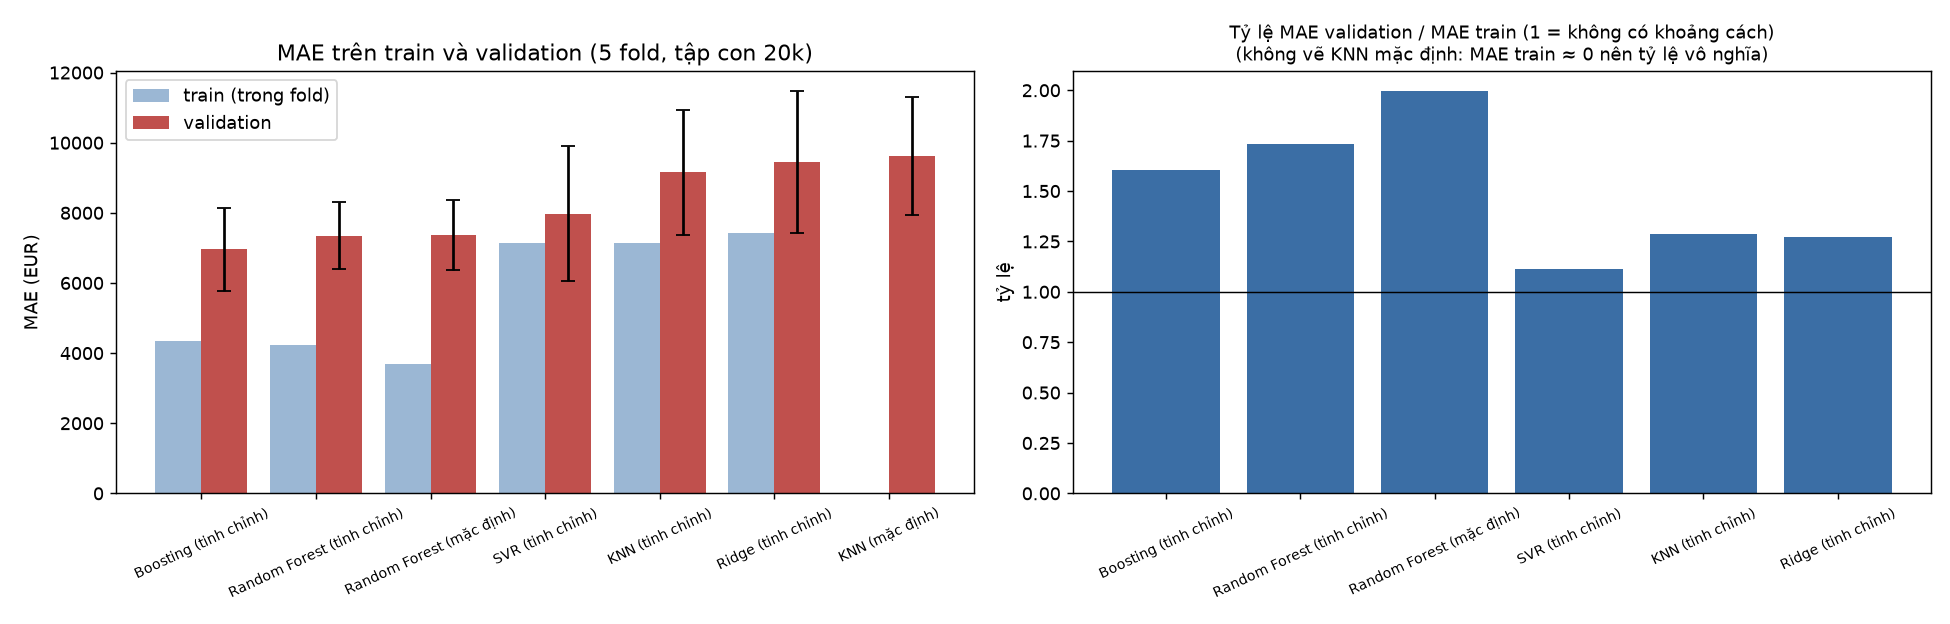

In [4]:
display(pd.read_csv(T / 'week3_diag_summary.csv'))
display(Image(str(F / 'week3_diag_train_valid.png')))

## 3. Độ quan trọng đặc trưng (permutation importance trên validation)

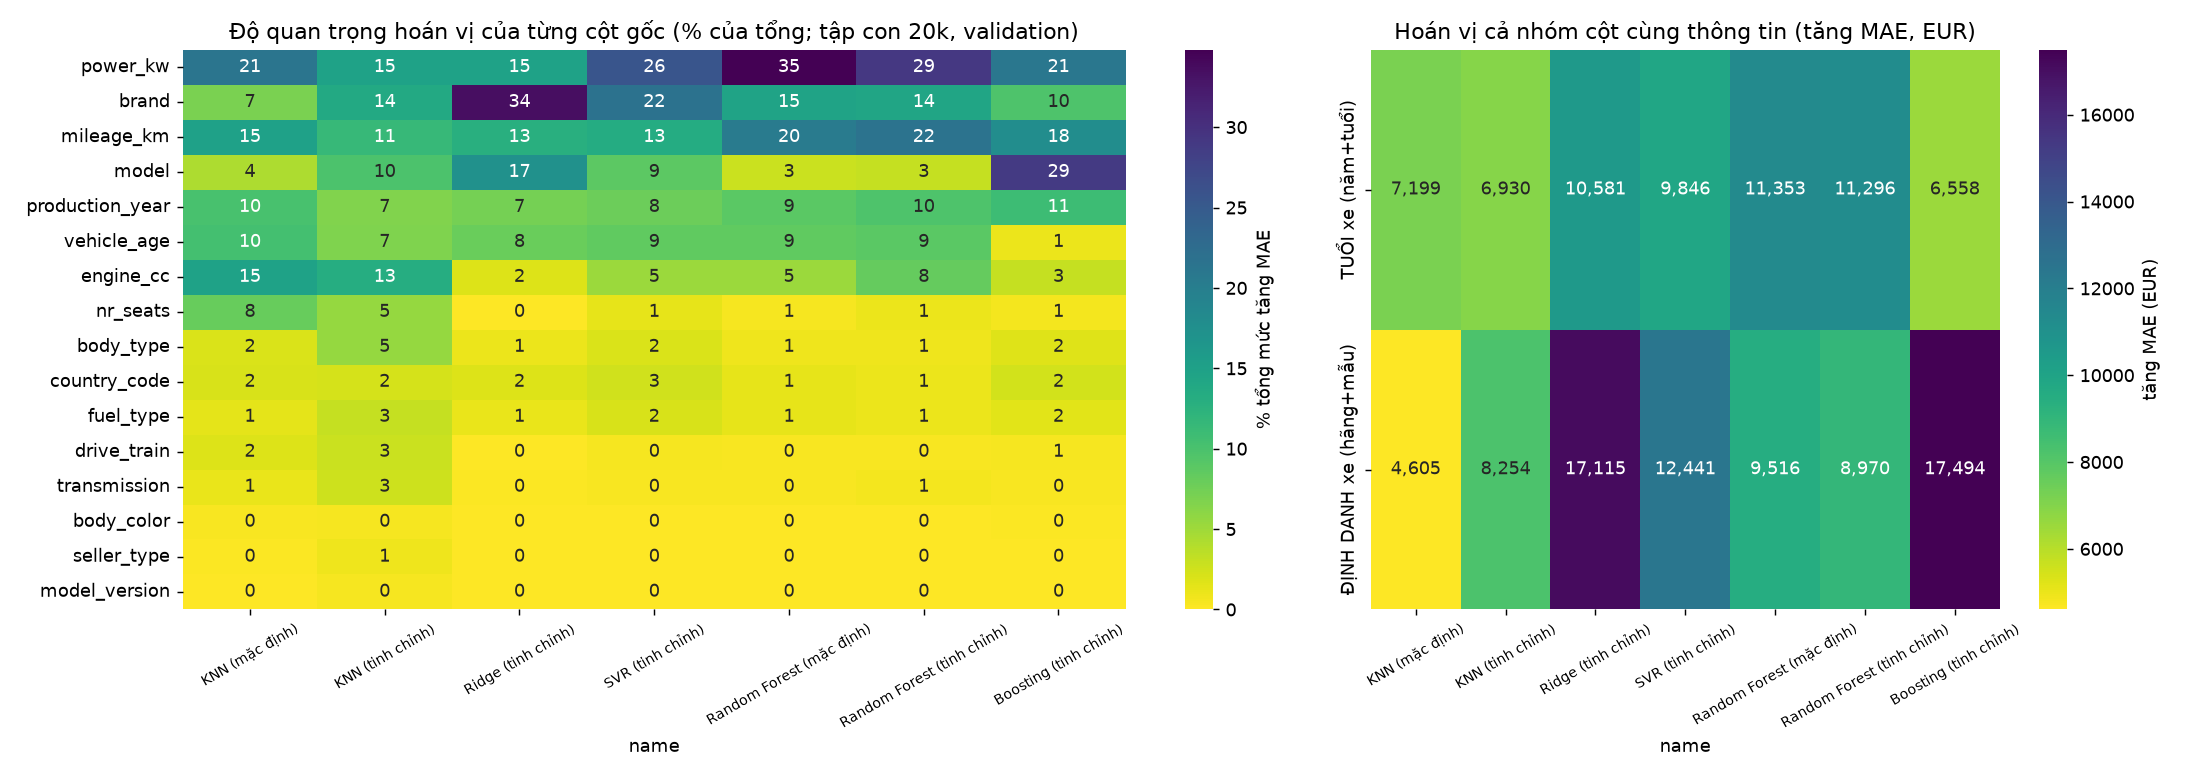

,name,data,feature,kind,delta_mae,delta_mae_std_folds,folds_positive,share_pct,rank_in_model
72,rf_tuned,dev20k,power_kw,single,"14,877.67","1,845.28",5,29.20,1
73,rf_tuned,dev20k,age (year+vehicle_age),joint,"11,295.54","3,075.40",5,NaN,2
74,rf_tuned,dev20k,mileage_km,single,"10,969.00","1,808.55",5,21.53,3
75,rf_tuned,dev20k,identity (brand+model[+version]),joint,"8,969.86",516.98,5,NaN,4
76,rf_tuned,dev20k,brand,single,"7,328.16",728.55,5,14.38,5
77,rf_tuned,dev20k,production_year,single,"4,959.39","1,656.68",5,9.73,6
78,rf_tuned,dev20k,vehicle_age,single,"4,516.29","1,359.70",5,8.87,7
79,rf_tuned,dev20k,engine_cc,single,"4,203.40",799.99,5,8.25,8
80,rf_tuned,dev20k,model,single,"1,572.08",296.96,5,3.09,9
81,rf_tuned,dev20k,country_code,single,516.88,65.08,5,1.01,10


In [5]:
display(Image(str(F / 'week3_importance.png')))
imp = pd.read_csv(T / 'week3_importance_summary.csv')
imp[(imp.data == 'dev20k') & (imp.name == 'rf_tuned')].head(12)

## 4. Đường cong học: vì sao Random Forest tinh chỉnh thua mặc định trên test?

,fraction,n_train_used,rf_default_mae,rf_tuned_mae,tuned_minus_default,folds_tuned_better,n_folds
0,0.15,"9,037.67","8,358.35","8,069.44",-288.91,3,3
1,0.30,"18,134.67","7,242.25","7,435.32",193.07,1,3
2,0.50,"30,194.00","7,013.47","7,438.22",424.75,0,3
3,1.00,"60,365.60","6,276.04","6,888.38",612.34,0,5


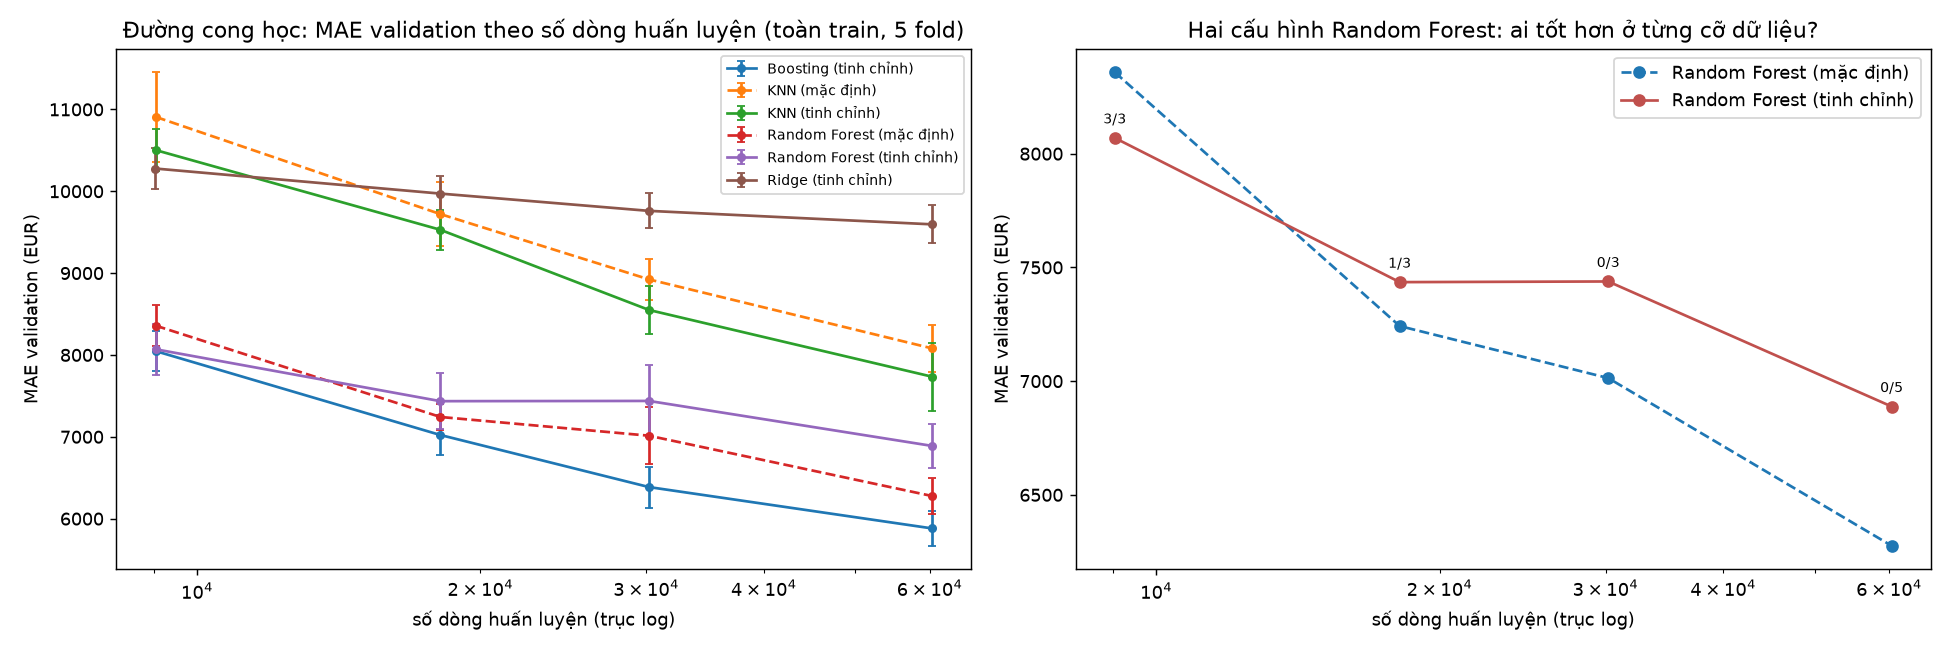

In [6]:
display(pd.read_csv(T / 'week3_rf_crossover.csv'))
display(Image(str(F / 'week3_learning_curves.png')))

## 5. Kết luận ngắn
- Boosting tinh chỉnh trên toàn train cho MAE CV thấp nhất trong các mô hình so sánh, nhưng **chưa có số liệu test** (chủ ý, tránh xem test lần hai).
- Các cột quyết định giá: nhóm định danh xe, công suất, tuổi xe, số km.
- Xem `reports/week3_extra_report.md` (Phụ lục A tự kiểm chứng phát biểu).